# Sri Lankan Used Vehicle Valuation: Ensemble & Hybrid Learning Pipeline

## Generative AI Attribution Statement
In accordance with the course Generative AI policy, I disclose that Generative AI tools were used as an auxiliary development aid in this assignment for scaffolding Python preprocessing pipelines, structuring the Streamlit dashboard layout, and debugging syntax. All dataset sourcing, Sri Lankan domain cleaning rules, model architecture configuration, evaluation analysis, and video explanations were independently executed and verified by the author.

## Project Scope
- **Domain:** Local Sri Lankan Used Vehicle Market (`ikman.lk` / `riyasewana.lk`), target priced in **LKR**.
- **Paradigms Implemented:**
  1. **Bagging:** Random Forest (with Out-of-Bag validation) & Extra Trees
  2. **Boosting:** AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost
  3. **Stacking:** Level-0 Heterogeneous Learners (Random Forest + XGBoost + ANN) blended via Level-1 Ridge Meta-Learner using 5-fold out-of-fold predictions
  4. **Hybrid Architecture:** Random Forest + Artificial Neural Network (Residual Learning Hybrid)

In [4]:
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Load raw dataset and inspect actual schema
raw_df = pd.read_csv("sl_vehicles.csv")
print("Raw Shape:", raw_df.shape)
print("Raw Columns:", list(raw_df.columns))
display(raw_df.head(3))

# 2. Smart column normalization (prevents duplicate mappings & handles variations)
col_map = {}
used_targets = set()

# Prioritize exact matches first, then substring matches
priority_rules = [
    ("price", lambda cl: cl == "price" or ("price" in cl and "type" not in cl and "neg" not in cl)),
    ("year", lambda cl: cl in ["yom", "year"] or "year" in cl or "yom" in cl or "manufactur" in cl),
    ("mileage", lambda cl: "millage" in cl or "mileage" in cl or "km" in cl),
    ("engine_cc", lambda cl: "engine" in cl or "cc" in cl or "capacity" in cl),
    ("brand", lambda cl: "brand" in cl or "make" in cl),
    ("model", lambda cl: "model" in cl),
    ("transmission", lambda cl: "gear" in cl or "transmission" in cl),
    ("fuel_type", lambda cl: "fuel" in cl),
    ("location", lambda cl: any(k in cl for k in ["town", "district", "location", "city", "area"])),
]

for target, matcher in priority_rules:
    for c in raw_df.columns:
        if c not in col_map and target not in used_targets and matcher(c.strip().lower()):
            col_map[c] = target
            used_targets.add(target)
            break

print("Mapped Columns:", col_map)
df = raw_df.rename(columns=col_map).copy()

# Helper to extract clean numeric values
def parse_numeric(series):
    return (
        series.astype(str)
        .str.replace(r"[^\d.]", "", regex=True)
        .replace("", np.nan)
        .astype(float)
    )

for num_col in ["price", "year", "mileage", "engine_cc"]:
    if num_col in df.columns:
        df[num_col] = parse_numeric(df[num_col])

# Fallback: if 'year' wasn't a separate column, extract 4-digit year from Title/Name if present
if "year" not in df.columns:
    for c in df.columns:
        if df[c].dtype == object:
            extracted = df[c].astype(str).str.extract(r"\b(19[89]\d|20[0-2]\d)\b")[0].astype(float)
            if extracted.notna().sum() > len(df) * 0.3:
                df["year"] = extracted
                print(f"Extracted 'year' from column '{c}'")
                break

# Auto-detect if Sri Lankan prices in this CSV are stored in Lakhs or Millions
if "price" in df.columns:
    df = df.dropna(subset=["price"]).copy()
    med_price = df["price"].median()
    if med_price < 200:
        print(f"Detected prices in Millions (median={med_price}); converting to LKR...")
        df["price"] = df["price"] * 1_000_000
    elif med_price < 10_000:
        print(f"Detected prices in Lakhs (median={med_price}); converting to LKR...")
        df["price"] = df["price"] * 100_000

    df = df[(df["price"] >= 100_000) & (df["price"] <= 200_000_000)]

if "year" in df.columns and df["year"].notna().sum() > 0:
    df = df[(df["year"].isna()) | ((df["year"] >= 1970) & (df["year"] <= 2026))]

if "mileage" in df.columns:
    df.loc[(df["mileage"] < 0) | (df["mileage"] > 1_000_000), "mileage"] = np.nan

# Select available features dynamically
CANDIDATE_NUM = ["year", "mileage", "engine_cc"]
CANDIDATE_CAT = ["brand", "model", "fuel_type", "transmission", "location"]

NUM_COLS = [c for c in CANDIDATE_NUM if c in df.columns and df[c].notna().sum() > 0]
CAT_COLS = [c for c in CANDIDATE_CAT if c in df.columns and df[c].notna().sum() > 0]

for c in CAT_COLS:
    df[c] = df[c].fillna("Unknown").astype(str).str.strip().str.title()

df = df[NUM_COLS + CAT_COLS + ["price"]].reset_index(drop=True)
print(f"\nCleaned Sri Lankan Dataset Shape: {df.shape}")
print("Numeric Features:", NUM_COLS)
print("Categorical Features:", CAT_COLS)
df.head()

Raw Shape: (9788, 17)
Raw Columns: ['Unnamed: 0', 'Brand', 'Model', 'YOM', 'Engine (cc)', 'Gear', 'Fuel Type', 'Millage(KM)', 'Town', 'Date', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW', 'Price']


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5


Mapped Columns: {'Price': 'price', 'YOM': 'year', 'Millage(KM)': 'mileage', 'Engine (cc)': 'engine_cc', 'Brand': 'brand', 'Model': 'model', 'Gear': 'transmission', 'Fuel Type': 'fuel_type', 'Town': 'location'}
Detected prices in Millions (median=43.0); converting to LKR...

Cleaned Sri Lankan Dataset Shape: (9626, 9)
Numeric Features: ['year', 'mileage', 'engine_cc']
Categorical Features: ['brand', 'model', 'fuel_type', 'transmission', 'location']


,year,mileage,engine_cc,brand,model,fuel_type,transmission,location,price
0,2016.0,99000.0,990.0,Audi,A1,Petrol,Automatic,Gampaha,100000000.0
1,2017.0,88000.0,1000.0,Audi,A1,Petrol,Automatic,Colombo,97000000.0
2,2018.0,77000.0,1000.0,Audi,A1,Petrol,Automatic,Dehiwala-Mount-Lavinia,98500000.0
3,2017.0,88000.0,1000.0,Audi,A1,Petrol,Automatic,Negombo,107000000.0
4,2017.0,88000.0,1000.0,Audi,A1,Petrol,Automatic,Colombo,99500000.0


C:\Users\nrame\AppData\Local\Temp\ipykernel_6624\2666121178.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_locs.values, y=top_locs.index, ax=axes[1], palette="viridis")


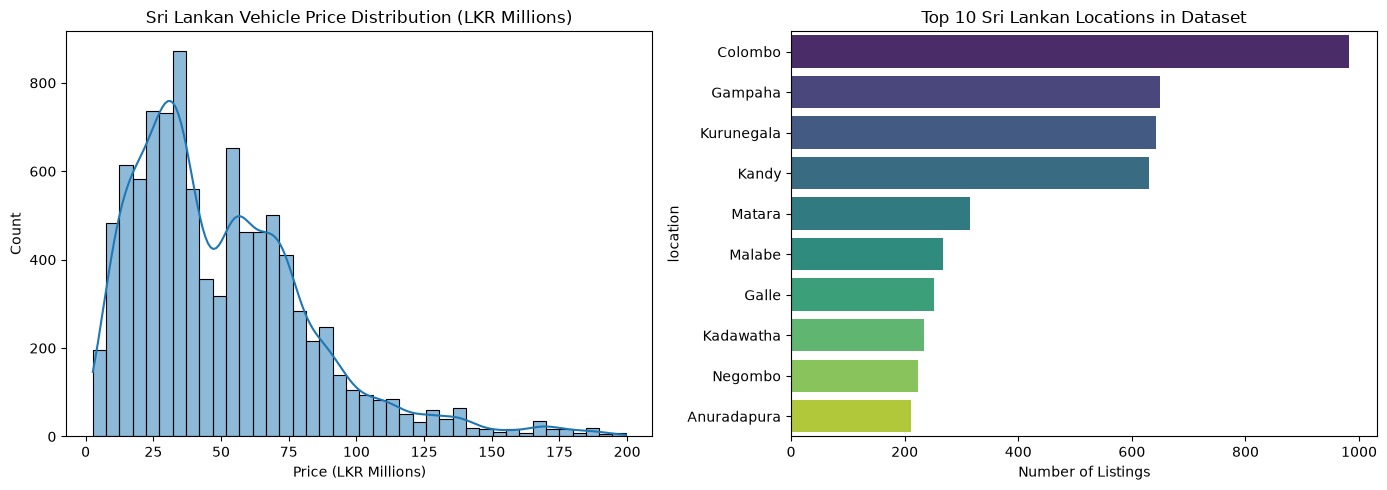

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Price distribution in LKR Millions
sns.histplot(df["price"] / 1e6, bins=40, kde=True, ax=axes[0], color="#1f77b4")
axes[0].set_title("Sri Lankan Vehicle Price Distribution (LKR Millions)")
axes[0].set_xlabel("Price (LKR Millions)")

# Plot 2: Top 10 Sri Lankan Towns/Districts by Listing Count
if "location" in df.columns:
    top_locs = df["location"].value_counts().head(10)
    sns.barplot(x=top_locs.values, y=top_locs.index, ax=axes[1], palette="viridis")
    axes[1].set_title("Top 10 Sri Lankan Locations in Dataset")
    axes[1].set_xlabel("Number of Listings")

plt.tight_layout()
plt.show()

In [6]:
X = df[NUM_COLS + CAT_COLS]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# min_frequency=5 groups ultra-rare vehicle trims cleanly without exploding dimensionality
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, NUM_COLS),
        ("cat", categorical_transformer, CAT_COLS),
    ]
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

print(f"Training matrix shape: {X_train_proc.shape}")
print(f"Testing matrix shape:  {X_test_proc.shape}")

Training matrix shape: (7700, 400)
Testing matrix shape:  (1926, 400)


In [7]:
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
    StackingRegressor
)
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from hybrid_model import RFANNHybridRegressor

models = {
    # 1. BAGGING
    "Bagging: Random Forest": RandomForestRegressor(
        n_estimators=200, oob_score=True, random_state=42, n_jobs=-1
    ),
    "Bagging: Extra Trees": ExtraTreesRegressor(
        n_estimators=200, random_state=42, n_jobs=-1
    ),

    # 2. BOOSTING
    "Boosting: AdaBoost": AdaBoostRegressor(
        n_estimators=150, learning_rate=0.05, random_state=42
    ),
    "Boosting: Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=5, random_state=42
    ),
    "Boosting: XGBoost": XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1
    ),
    "Boosting: LightGBM": LGBMRegressor(
        n_estimators=300, learning_rate=0.05, random_state=42, verbose=-1
    ),
    "Boosting: CatBoost": CatBoostRegressor(
        iterations=300, learning_rate=0.05, depth=6, random_seed=42, verbose=0
    ),

    # 3. STACKING (Out-of-Fold Cross-Validation prevents meta-learner data leakage)
    "Stacking: RF + XGB + ANN -> Ridge": StackingRegressor(
        estimators=[
            ("rf", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
            ("xgb", XGBRegressor(n_estimators=150, learning_rate=0.05, random_state=42, n_jobs=-1)),
            ("ann", MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=400, early_stopping=True, random_state=42))
        ],
        final_estimator=Ridge(alpha=1.0),
        cv=5,
        n_jobs=-1
    ),

    # 4. HYBRID ARCHITECTURE (Tree Decision Boundaries + Neural Residual Smoothing)
    "Hybrid: Random Forest + ANN": RFANNHybridRegressor(
        rf_estimators=200, ann_layers=(128, 64), random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_proc, y_train)
    preds = model.predict(X_test_proc)

    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    row = {
        "Model": name,
        "RMSE (LKR)": round(rmse, 2),
        "MAE (LKR)": round(mae, 2),
        "R2 Score": round(r2, 4),
        "OOB R2": round(model.oob_score_, 4) if hasattr(model, "oob_score_") else None
    }
    results.append(row)
    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(by="RMSE (LKR)").reset_index(drop=True)
results_df

Training Bagging: Random Forest...
Training Bagging: Extra Trees...
Training Boosting: AdaBoost...
Training Boosting: Gradient Boosting...
Training Boosting: XGBoost...
Training Boosting: LightGBM...
Training Boosting: CatBoost...
Training Stacking: RF + XGB + ANN -> Ridge...
Training Hybrid: Random Forest + ANN...


,Model,RMSE (LKR),MAE (LKR),R2 Score,OOB R2
0,Bagging: Extra Trees,8963922.89,4278089.49,0.9240,NaN
1,Hybrid: Random Forest + ANN,9321797.70,4350649.38,0.9178,NaN
2,Bagging: Random Forest,9321819.21,4350663.98,0.9178,0.9284
3,Stacking: RF + XGB + ANN -> Ridge,9414024.83,4564980.43,0.9162,NaN
4,Boosting: XGBoost,10070397.90,5235626.62,0.9041,NaN
5,Boosting: LightGBM,10291578.53,5253085.05,0.8998,NaN
6,Boosting: Gradient Boosting,10503966.76,5806437.69,0.8957,NaN
7,Boosting: CatBoost,10762610.97,6071636.30,0.8905,NaN
8,Boosting: AdaBoost,18080591.07,12510833.51,0.6909,NaN


C:\Users\nrame\AppData\Local\Temp\ipykernel_6624\3870376661.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="RMSE (LKR)", y="Model", palette="coolwarm")


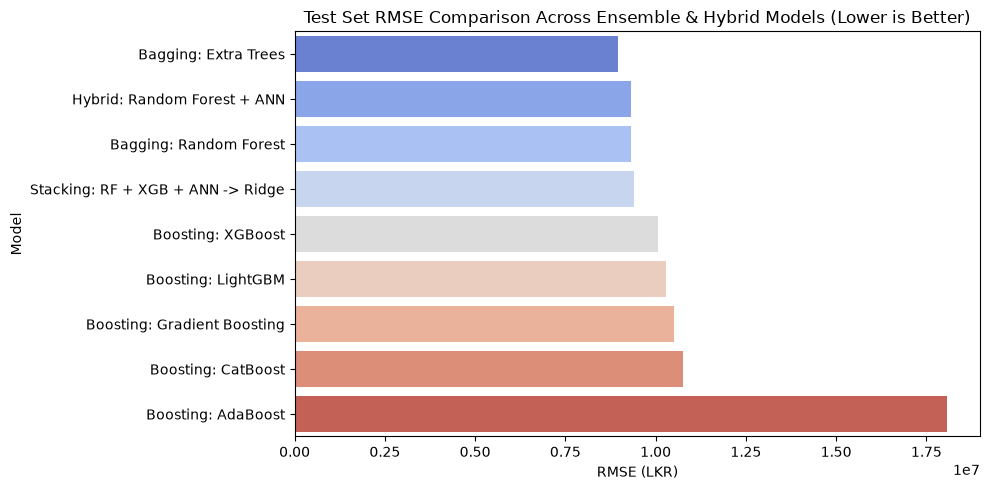

Saved model_bundle.joblib successfully!


In [8]:
# Plot RMSE comparison
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="RMSE (LKR)", y="Model", palette="coolwarm")
plt.title("Test Set RMSE Comparison Across Ensemble & Hybrid Models (Lower is Better)")
plt.tight_layout()
plt.show()

# Extract Top 15 Feature Importances from Random Forest
rf_model = trained_models["Bagging: Random Forest"]
feat_imp_df = (
    pd.DataFrame({"Feature": feature_names, "Importance": rf_model.feature_importances_})
    .sort_values(by="Importance", ascending=False)
    .head(15)
)

# Build brand -> models lookup dictionary so the UI filters models dynamically by selected brand
brand_model_map = {}
if "brand" in CAT_COLS and "model" in CAT_COLS:
    for b, grp in X.groupby("brand"):
        brand_model_map[b] = sorted(grp["model"].unique().tolist())

ui_options = {col: sorted(X[col].unique().tolist()) for col in CAT_COLS}
num_defaults = {
    col: {
        "min": float(X[col].min()),
        "max": float(X[col].max()),
        "median": float(X[col].median())
    }
    for col in NUM_COLS
}

bundle = {
    "preprocessor": preprocessor,
    "models": trained_models,
    "metrics": results_df,
    "feature_importance": feat_imp_df,
    "num_cols": NUM_COLS,
    "cat_cols": CAT_COLS,
    "ui_options": ui_options,
    "brand_model_map": brand_model_map,
    "num_defaults": num_defaults,
    "sample_rows": X_test.head(10).to_dict(orient="records"),
    "sample_actuals": y_test.head(10).tolist()
}

joblib.dump(bundle, "model_bundle.joblib")
print("Saved model_bundle.joblib successfully!")